# Automated Geometric Feature Extraction of Namdokmai Sithong Mangoes (YOLOv8 + Image Processing)

Reproduction of the minimal measurement pipeline from:

**Sujitra Arwatchananukul, Suphapol Wongsawat, Saowapa Chaiwong, Min Chen, Rattapon Saengrayap.**
*Automated Physical Feature Extraction of Namdokmai Sithong Mangoes Using YOLOv8 and Image Processing Techniques.*
**AgriEngineering** 2025, 7(9), 312. DOI: [10.3390/agriengineering7090312](https://doi.org/10.3390/agriengineering7090312)

Author code (pinned commit `05fbc382316a34afed55dd1499341063d8d2eae4`): https://github.com/sujitrajingjing/Namdokmai-Sithong-Geometric-Feature-Extraction-

**Scope (partial demonstration).** Run the authors' YOLOv8 fruit+peduncle detection and HSV-based axis measurement on the **single bundled sample image** `input.jpg`, reproducing `main.py::run_detection` and `functions.py::draw_bounding_boxes` headlessly. **Not included:** the 30-image evaluation, dataset download, training, and the desktop GUI.

**AI-assisted adaptation notice / AIによる移植に関する注意:** The authors released a desktop GUI application (`customtkinter`), not a Colab notebook. This notebook is an **AI-assisted headless port**: `functions.py` is imported **verbatim** from the pinned commit, and the GUI orchestration of `main.py` is re-implemented as notebook cells with line-cited mapping. The executed example and listed checks were validated, but untested behavior is not guaranteed. / 著者はGUIアプリとして公開しており、Colab実装は本ノートブックがAIによりheadless移植したものです。`functions.py`はピン留めコミットからそのまま取り込み、GUI部分のみ同等の処理をセル化しています。

**Runtime.** A CPU runtime is sufficient (model ≈ 6 MB, single image). No GPU needed. / CPUランタイムで十分です。

**Calibration caveat.** The GUI asks the user for a pixel-per-cm value (`PIXEL_PER_CM`) and a down-scaling percentage (`IMAGE_SCALE`). No source states the values for `input.jpg`, so this notebook uses a clearly labeled **assumed** calibration; pixel measurements are the faithful primary results. / ピクセル/cm換算値は資料に明示がないため、仮定値を明示して使用します。


## Run all / 実行方法

Select **Runtime → Run all** on a **CPU** runtime (recommended; a T4 GPU also works but adds nothing). Expected total time on CPU: roughly 3–6 minutes, dominated by the `ultralytics` install and the axis-search loop. Downloads: ~7 MB (model + sample image) plus pip packages. / CPUランタイムで「ランタイム → すべてのセルを実行」。所要時間は概ね3〜6分、ダウンロードは約7MB+パッケージです。

Limitations: single-sample demonstration (not a validation of the paper's 30-image error statistics); `PIXEL_PER_CM` is an assumption; the authors' "perimeter" metric is a Canny edge-pixel count, preserved as-is. / 単一サンプルのデモであり、30枚評価の再現ではありません。


## 1. Environment setup / 環境セットアップ

Install the authors' pinned `ultralytics==8.2.31` (from their `requirements.txt`, commit `05fbc382316a34afed55dd1499341063d8d2eae4`), which brings OpenCV. Two documented deviations, verified diagnostically on this runtime: (a) `customtkinter==5.2.2` (desktop GUI toolkit) is **not** installed — GUI only; (b) the authors' `numpy==1.26.4` pin is **not** imposed: the current Colab image (Python 3.13) has no 1.26.4 wheel and pip's resolver retains its preinstalled NumPy (≥2), while the authors' own constraint is `numpy>=1.23` and the author functions verified working with the retained NumPy. Pillow is likewise left at the preinstalled version (their code uses PIL only inside the GUI). Expected result: a quiet successful install. / 著者の`ultralytics==8.2.31`をインストールします。GUI専用の`customtkinter`は省略、NumPy/Pillowは現在のColabイメージ同梱版を使用します（著者制約`numpy>=1.23`は満たす）。

In [ ]:
%pip install -q "ultralytics==8.2.31"
import sys
print("python", sys.version.split()[0])

python 3.13.16


## 2. Acquire the pinned author assets / ピン留めアセットの取得

Download `model.pt` (trained YOLOv8 weights, 6,245,155 bytes), the bundled sample `input.jpg` (867,565 bytes), and the authors' `functions.py` (14,766 bytes) from **raw.githubusercontent.com at the exact pinned commit** `05fbc382316a34afed55dd1499341063d8d2eae4`. Verify each file by size and **Git blob SHA-1** (computed from the file bytes), which must equal the values in the pinned commit's tree metadata: `model.pt` → `8362a27e0f5fe8fae27ffbd0cce8d739b12ffe0f`, `input.jpg` → `077edbb30b6345a0770aece903a0309e2387b70a`, `functions.py` → `47e8c960aaac12cb4dfb45509d0999d50c3dc113`. Expected result: three `OK` lines. / モデル・サンプル画像・作者コードをピン留めコミットからダウンロードし、サイズとGit blob SHA-1で検証します。

In [ ]:
import hashlib
import urllib.request
from pathlib import Path

REPO = "sujitrajingjing/Namdokmai-Sithong-Geometric-Feature-Extraction-"
COMMIT = "05fbc382316a34afed55dd1499341063d8d2eae4"
BASE = f"https://raw.githubusercontent.com/{REPO}/{COMMIT}"

# Sizes and Git blob SHA-1s from the pinned commit's tree metadata (GitHub API, retrieved 2026-10-26)
EXPECTED = {
    "model.pt": (6245155, "8362a27e0f5fe8fae27ffbd0cce8d739b12ffe0f"),
    "input.jpg": (867565, "077edbb30b6345a0770aece903a0309e2387b70a"),
    "functions.py": (14766, "47e8c960aaac12cb4dfb45509d0999d50c3dc113"),
}

def git_blob_sha1(data: bytes) -> str:
    """Git blob object name: sha1('blob <size>\x00' + content)."""
    return hashlib.sha1(b"blob %d\x00" % len(data) + data).hexdigest()

DATA_DIR = Path("/content/mango_colab")
DATA_DIR.mkdir(parents=True, exist_ok=True)

for name, (size, sha) in EXPECTED.items():
    dest = DATA_DIR / name
    if not dest.exists() or git_blob_sha1(dest.read_bytes()) != sha:
        urllib.request.urlretrieve(f"{BASE}/{name}", dest)
    data = dest.read_bytes()
    assert len(data) == size, f"{name}: size {len(data)} != {size}"
    assert git_blob_sha1(data) == sha, f"{name}: blob SHA mismatch"
    print(f"{name}: OK ({len(data)} bytes, git blob {sha[:12]}...)")

model.pt: OK (6245155 bytes, git blob 8362a27e0f5f...)


input.jpg: OK (867565 bytes, git blob 077edbb30b63...)
functions.py: OK (14766 bytes, git blob 47e8c960aaac...)


## 3. Load the author's measurement code and the trained model / 著者コードとモデルの読み込み

Import the authors' `functions.py` **verbatim** (it contains the entire scientific pipeline: HSV inverse mask, morphology, Canny edges, axis search) and load `model.pt` through `ultralytics.YOLO`, exactly as `main.py` line 224 (`model = YOLO(get_file_path('model.pt'))`).

**Labeled compatibility patch (AI-generated).** The authors' environment predates PyTorch 2.6; from torch 2.6 `torch.load` defaults to `weights_only=True`, which rejects their checkpoint. The cell restores the authors' behavior for this **hash-verified** file only, via `torch.load` with `weights_only=False` — the standard documented workaround; no weights are substituted. Print library versions and the model's class names so the class-index semantics used below are read from the checkpoint itself, not assumed. / torch 2.6以降の`weights_only`既定変更に対し、検証済みチェックポイントを読み込むための互換パッチ（AI生成・明記）を適用します。

In [ ]:
import sys
import time

sys.path.insert(0, str(DATA_DIR))
import functions  # authors' pinned functions.py, used verbatim

import cv2
import numpy as np
import PIL
import torch
import ultralytics
from ultralytics import YOLO

print("torch", torch.__version__, "| CUDA available:", torch.cuda.is_available())
print("ultralytics", ultralytics.__version__, "| numpy", np.__version__,
      "| opencv", cv2.__version__, "| Pillow", PIL.__version__)

# AI compatibility patch for torch>=2.6: authors' env used the pre-2.6 default (weights_only=False).
# Applied only to load their blob-SHA-verified model.pt; no weights are modified or substituted.
# Idempotent guard: never double-wrap on notebook re-run.
if not getattr(torch.load, "_mango_pre26_compat", False):
    _original_torch_load = torch.load
    def _torch_load_pre26(*args, **kwargs):
        kwargs.setdefault("weights_only", False)
        return _original_torch_load(*args, **kwargs)
    _torch_load_pre26._mango_pre26_compat = True
    torch.load = _torch_load_pre26

model = YOLO(str(DATA_DIR / "model.pt"))
print("Model class names:", model.names)

torch 2.11.0+cpu | CUDA available: False
ultralytics 8.2.31 | numpy 2.1.3 | opencv 5.0.0 | Pillow 11.3.0
Model class names: {0: 'fruit', 1: 'peduncle'}


## 4. Input preview / 入力画像のプレビュー

Decode and show the bundled author sample `input.jpg` (provenance: pinned commit `05fbc38`, verified above) before any analysis, per the reproducibility protocol. Expected result: the mango photograph with its printed dimensions. / 分析前にサンプル画像`input.jpg`を表示し、寸法を確認します。

input.jpg: 2328x1218 px (BGR)


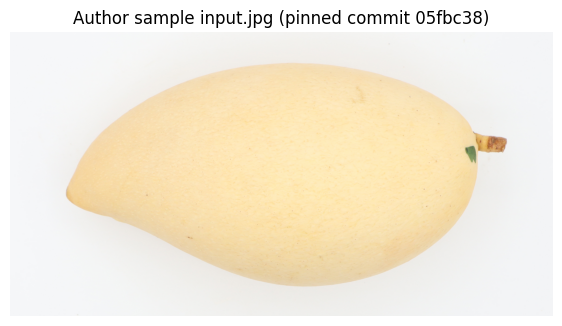

In [ ]:
import matplotlib.pyplot as plt

src_img = cv2.imread(str(DATA_DIR / "input.jpg"))
assert src_img is not None, "input.jpg could not be decoded"
h, w = src_img.shape[:2]
print(f"input.jpg: {w}x{h} px (BGR)")

plt.figure(figsize=(7, 7))
plt.imshow(cv2.cvtColor(src_img, cv2.COLOR_BGR2RGB))
plt.title("Author sample input.jpg (pinned commit 05fbc38)")
plt.axis("off")
plt.show()

## 5. Calibration inputs (GUI mapping) / キャリブレーション入力（GUI対応の置き換え）

`main.py` opens two dialogs before processing: `CalibrationWindow` ("Enter Pixel per CM value") and `ScaleWindow` ("Enter % for down scaling"). This notebook supplies both headlessly:

| GUI input | Here | Value | Basis |
| --- | --- | --- | --- |
| Pixel per CM | `PIXEL_PER_CM` | **100.0 (ASSUMED)** | No source states a value for `input.jpg`; cm outputs are conditional on this assumption — replace it with a value measured from your calibration marker. |
| % down scaling | `IMAGE_SCALE` | **100** (no rescale) | No documented default; 100 keeps original resolution so the ×100/`IMAGE_SCALE` rescale factor is exactly 1. |

Expected result: the two constants echoed. / GUIの2つのダイアログ入力をヘッドレス定数に置き換えます。`PIXEL_PER_CM`は仮定値（ピクセル値が一次結果）、`IMAGE_SCALE=100`は無縮小を意味します。

In [ ]:
# main.py CalibrationWindow / ScaleWindow, supplied headlessly (AI adaptation)
PIXEL_PER_CM = 100.0   # ASSUMED for demonstration only -- replace with your measured calibration
IMAGE_SCALE = 100.0    # % down-scaling; 100 = original resolution

assert 0 < IMAGE_SCALE <= 100 and PIXEL_PER_CM > 0
print(f"PIXEL_PER_CM = {PIXEL_PER_CM} (assumed) | IMAGE_SCALE = {IMAGE_SCALE}%")

PIXEL_PER_CM = 100.0 (assumed) | IMAGE_SCALE = 100.0%


## 6. YOLOv8 detection on the sample / YOLOv8検出

Headless port of `main.py::run_detection` (pinned commit, `process_image`, lines ≈230–257): rescale with the authors' `scaleImage`, then `model(img, conf=0.25, max_det=10)` with the authors' exact inference settings, then keep the **top-confidence** box of class 0 and of class 1 (`main.py` lines 246–257). `functions.get_overlapping_area` then checks that fruit and peduncle boxes overlap, as in `main.py` line 267. Deviation: if a class is missing the author code would either skip (`len(boxes)==1`) or crash on an empty box list; here it raises a clear `RuntimeError`. Expected result: confidence values for both classes and a non-None overlap rectangle. / `main.py`の検出処理（conf=0.25, max_det=10、クラス0/1の最も信頼度の高いボックス）をそのまま再現し、重なり判定まで行います。

In [ ]:
# Port of main.py process_image() detection section (pinned commit 05fbc38, lines ~230-257)
img = functions.scaleImage(src_img, scale_percent=IMAGE_SCALE)

t0 = time.time()
results = model(img, conf=0.25, max_det=10)  # authors' inference settings
t_infer = time.time() - t0
print(f"Inference: {t_infer:.1f} s on {'GPU' if torch.cuda.is_available() else 'CPU'}")

top_conf = {0: 0.0, 1: 0.0}
xy = {0: None, 1: None}
for r in results:
    for box in r.boxes.cpu().numpy():
        cls = int(box.cls[0])
        conf = float(box.conf[0])
        if conf > top_conf[cls]:
            top_conf[cls] = conf
            xy[cls] = box.xyxy[0].tolist()

if xy[0] is None or xy[1] is None:
    raise RuntimeError("Fruit or peduncle not detected (author message: 'Fruit or peduncle not detected'). "
                       f"Top confidences by class: { {k: round(v, 3) for k, v in top_conf.items()} }")

bbox1, bbox2 = xy[0], xy[1]  # author order: class 0 (fruit) first, class 1 (peduncle) second
overlapping_area = functions.get_overlapping_area(bbox1, bbox2)
if overlapping_area is None:
    raise RuntimeError("No overlap between bounding boxes (author code path).")

print("bbox1 (class 0):", [round(v, 1) for v in bbox1], f"conf={top_conf[0]:.3f}")
print("bbox2 (class 1):", [round(v, 1) for v in bbox2], f"conf={top_conf[1]:.3f}")
print("Overlap:", [round(v, 1) for v in overlapping_area])

0: 352x640 1 fruit, 2 peduncles, 284.4ms


Speed: 10.2ms preprocess, 284.4ms inference, 40.1ms postprocess per image at shape (1, 3, 352, 640)


Inference: 6.7 s on CPU
bbox1 (class 0): [239.8, 121.9, 2014.3, 1113.4] conf=0.934
bbox2 (class 1): [1984.2, 424.7, 2134.3, 522.2] conf=0.823
Overlap: [1984.2, 424.7, 2014.3, 522.2]


## 7. Axis measurement / 軸長測定

Run the authors' `functions.draw_bounding_boxes` **unmodified** (it draws the fruit/peduncle/overlap boxes, computes the HSV inverse mask + morphological cleanup, counts area and Canny-edge-pixel "perimeter", finds the mask centroid inside the overlap region, and searches 0.25°-increment rays from the centroid for the longest line — the major axis — plus the two longest perpendicular lines, the top/bottom minor widths; `functions.py` lines 18–197). Then apply `main.py` lines 284–291: rescale to original pixels (×100/`IMAGE_SCALE`) and divide by `PIXEL_PER_CM` for cm. Expected result: pixel and cm values for the major axis and both minor axes, plus area/perimeter counts. / 著者の`draw_bounding_boxes`をそのまま実行し、`main.py`の式（×100/IMAGE_SCALE、÷PIXEL_PER_CM）でcm換算します。

In [ ]:
# Authors' measurement core, verbatim (functions.py draw_bounding_boxes)
image_bbox_drawn, data, major_loc, minor1_loc, minor2_loc = functions.draw_bounding_boxes(
    img, bbox1, bbox2, overlapping_area
)

# main.py lines ~284-291: rescale to original resolution, convert px -> cm
for key in ("Longest Line", "Perpendicular Line 1", "Perpendicular Line 2", "area", "perimeter"):
    data[key] = data[key] * 100.0 / IMAGE_SCALE
data["Longest Line (cm)"] = data["Longest Line"] / PIXEL_PER_CM
data["Perpendicular Line 1 (cm)"] = data["Perpendicular Line 1"] / PIXEL_PER_CM
data["Perpendicular Line 2 (cm)"] = data["Perpendicular Line 2"] / PIXEL_PER_CM
data["name"] = "input"

for k, v in data.items():
    print(f"{k}: {round(v, 2) if isinstance(v, float) else v}")

Longest line length: 1771.13 pixels
Perpendicular line1 length: 455.83 pixels
Perpendicular line2 length: 522.44 pixels
Longest Line: 1771.13
Perpendicular Line 1: 455.83
Perpendicular Line 2: 522.44
area: 1256148.0
perimeter: 4624.0
Longest Line (cm): 17.71
Perpendicular Line 1 (cm): 4.56
Perpendicular Line 2 (cm): 5.22
name: input


## 8. Annotated result and CSV export / 结果の可視化とCSV出力

Reproduce `main.py` lines 292–317: overlay the axis labels ("Major axis / Minor axis 1 / Minor axis 2", pixels and CM) with the authors' colors and font, save the annotated PNG and the 9-column `detection.csv` via the authors' `save_to_csv`, show the measurements as a table, and display the annotated image. The cm labels inherit the **assumed** calibration from cell 5. Expected result: the table, one annotated image, and files under `/content/mango_colab/output/`. / `main.py`の描画・CSV保存処理を再現し、注釈付き画像と表を表示します（cm値は仮定キャリブレーションに依存）。

,name,Longest Line,Perpendicular Line 1,Perpendicular Line 2,area,perimeter,Longest Line (cm),Perpendicular Line 1 (cm),Perpendicular Line 2 (cm)
0,input,1771.128736,455.8344,522.444255,1256148.0,4624.0,17.711287,4.558344,5.224443


Saved: /content/mango_colab/output/detection.csv and /content/mango_colab/output/input_detection.png


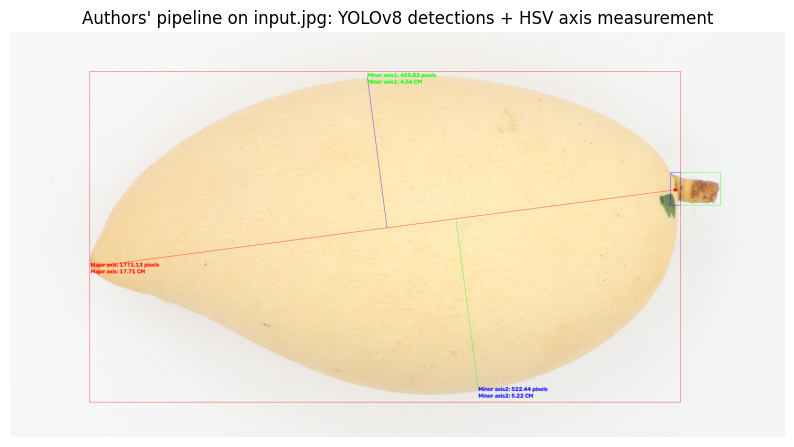

In [ ]:
# Port of main.py annotation + CSV section (pinned commit 05fbc38, lines ~292-317)
font, font_scale, thick = cv2.FONT_HERSHEY_DUPLEX, 0.6, 1
image_bbox_drawn = cv2.putText(
    image_bbox_drawn, f"Major axis: {round(data['Longest Line'], 2)} pixels", major_loc,
    font, font_scale, functions.color_red, thick)
image_bbox_drawn = cv2.putText(
    image_bbox_drawn, f"Minor axis1: {round(data['Perpendicular Line 1'], 2)} pixels", minor1_loc,
    font, font_scale, functions.color_green, thick)
image_bbox_drawn = cv2.putText(
    image_bbox_drawn, f"Minor axis2: {round(data['Perpendicular Line 2'], 2)} pixels", minor2_loc,
    font, font_scale, functions.color_blue, thick)
image_bbox_drawn = cv2.putText(
    image_bbox_drawn, f"Major axis: {round(data['Longest Line (cm)'], 2)} CM",
    (major_loc[0], major_loc[1] + 20), font, font_scale, functions.color_red, thick)
image_bbox_drawn = cv2.putText(
    image_bbox_drawn, f"Minor axis1: {round(data['Perpendicular Line 1 (cm)'], 2)} CM",
    (minor1_loc[0], minor1_loc[1] + 20), font, font_scale, functions.color_green, thick)
image_bbox_drawn = cv2.putText(
    image_bbox_drawn, f"Minor axis2: {round(data['Perpendicular Line 2 (cm)'], 2)} CM",
    (minor2_loc[0], minor2_loc[1] + 20), font, font_scale, functions.color_blue, thick)

OUT_DIR = DATA_DIR / "output"
OUT_DIR.mkdir(parents=True, exist_ok=True)
cv2.imwrite(str(OUT_DIR / "input_detection.png"), image_bbox_drawn)

headers = ["name", "Longest Line", "Perpendicular Line 1", "Perpendicular Line 2",
           "area", "perimeter", "Longest Line (cm)", "Perpendicular Line 1 (cm)",
           "Perpendicular Line 2 (cm)"]
functions.save_to_csv(str(OUT_DIR / "detection.csv"), headers, [data])

import pandas as pd
df = pd.read_csv(str(OUT_DIR / "detection.csv"))
display(df)
print(f"Saved: {OUT_DIR / 'detection.csv'} and {OUT_DIR / 'input_detection.png'}")

plt.figure(figsize=(10, 10))
plt.imshow(cv2.cvtColor(image_bbox_drawn, cv2.COLOR_BGR2RGB))
plt.title("Authors' pipeline on input.jpg: YOLOv8 detections + HSV axis measurement")
plt.axis("off")
plt.show()

## 9. Interpretation and limitations / 結果の解釈と限界

- **What was reproduced:** the authors' full single-image measurement path — YOLOv8 fruit/peduncle detection (conf=0.25, top-confidence boxes), HSV-based segmentation with morphological cleanup, Canny edges, centroid-guided major-axis search (0.25° increments) and the two longest perpendicular minor axes, px→cm conversion — with `functions.py` imported verbatim from pinned commit `05fbc38`.
- **What this does not show:** the paper's 30-image evaluation (error < 5% in >90% of samples, average length deviation < 1.5%) is **not** reproduced here; that would require the Kaggle dataset and its ground-truth split. A single successful sample does not validate dataset-level accuracy.
- **Assumptions:** `PIXEL_PER_CM = 100` is an assumption for demonstration (no source states the calibration for `input.jpg`) — the pixel values are the faithful primary results; `IMAGE_SCALE = 100` means no rescaling. The authors' "perimeter" is a Canny edge-pixel count and is reported as such.
- **Provenance:** paper DOI 10.3390/agriengineering7090312; code `sujitrajingjing/Namdokmai-Sithong-Geometric-Feature-Extraction-` @ `05fbc382316a34afed55dd1499341063d8d2eae4` (no LICENSE file in the repository — reuse terms unverified). AI-assisted headless port of the `customtkinter` GUI as stated at the top.

**日本語の要約:** 本ノートブックは著者コード（コミット`05fbc38`）の`functions.py`をそのまま用い、GUIアプリ`main.py`の処理をヘッドレス化したものです。YOLOv8で果実と果梗を検出し、HSVセグメンテーション・形態学的処理・Cannyエッジ・重心からの主軸／副軸探索により果実の長さと上下幅を測定します。ピクセル値が本来の結果で、cm値は仮定のキャリブレーション（100 px/cm）に依存します。30枚画像での誤差評価は本デモの範囲外です。